# Datheon Internship — Task 03
## Predictive Customer Churn Classification

### Random Forest & XGBoost

**Objective:** Build, evaluate, and compare machine learning
classifiers to predict customer churn using telecom subscription data.

**Techniques:** EDA, preprocessing pipelines, class imbalance
handling, cross-validation, hyperparameter tuning,
ROC-AUC evaluation, explainability, and model persistence.

## Step 01 - Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 02 - Load Dataset

In [2]:
DATA_PATH = Path("Telco-Customer-Churn.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 03 - Dataset Inspection

In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Customer IDs:")
print(df["customerID"].duplicated().sum())

print("\nTarget Distribution:")
display(df["Churn"].value_counts())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate Customer IDs:
0

Target Distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 04 - Data Cleaning

In [4]:
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Remove identifier column
df_clean = df_clean.drop(columns=["customerID"])

# Encode target variable
df_clean["Churn"] = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

if df_clean["Churn"].isna().any():
    raise ValueError("Invalid target labels found.")

df_clean["Churn"] = df_clean["Churn"].astype(int)

print("Cleaned Dataset Shape:", df_clean.shape)
print("Missing TotalCharges:", df_clean["TotalCharges"].isna().sum())

print("\nChurn Distribution:")
display(df_clean["Churn"].value_counts())

print("\nRemaining Missing Values:")
display(
    df_clean.isna().sum()
    .loc[lambda x: x > 0]
    .to_frame("Missing Count")
)

Cleaned Dataset Shape: (7043, 20)
Missing TotalCharges: 11

Churn Distribution:


Churn
0    5174
1    1869
Name: count, dtype: int64


Remaining Missing Values:


,Missing Count
TotalCharges,11


## Step 05 - Exploratory Data Analysis

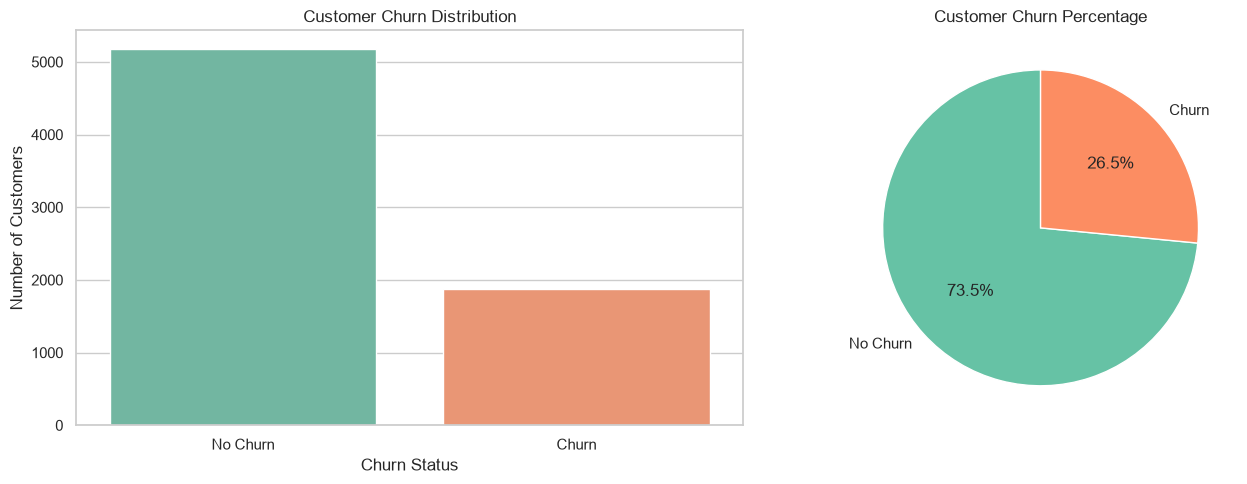

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Customer churn count
sns.countplot(
    data=df_clean,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Churn Distribution")
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Number of Customers")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Churn", "Churn"])

# Churn percentage
churn_counts = df_clean["Churn"].value_counts().reindex([0, 1])

axes[1].pie(
    churn_counts.values,
    labels=["No Churn", "Churn"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#66c2a5", "#fc8d62"]
)

axes[1].set_title("Customer Churn Percentage")

plt.tight_layout()
plt.show()

## Step 06 - Feature Analysis

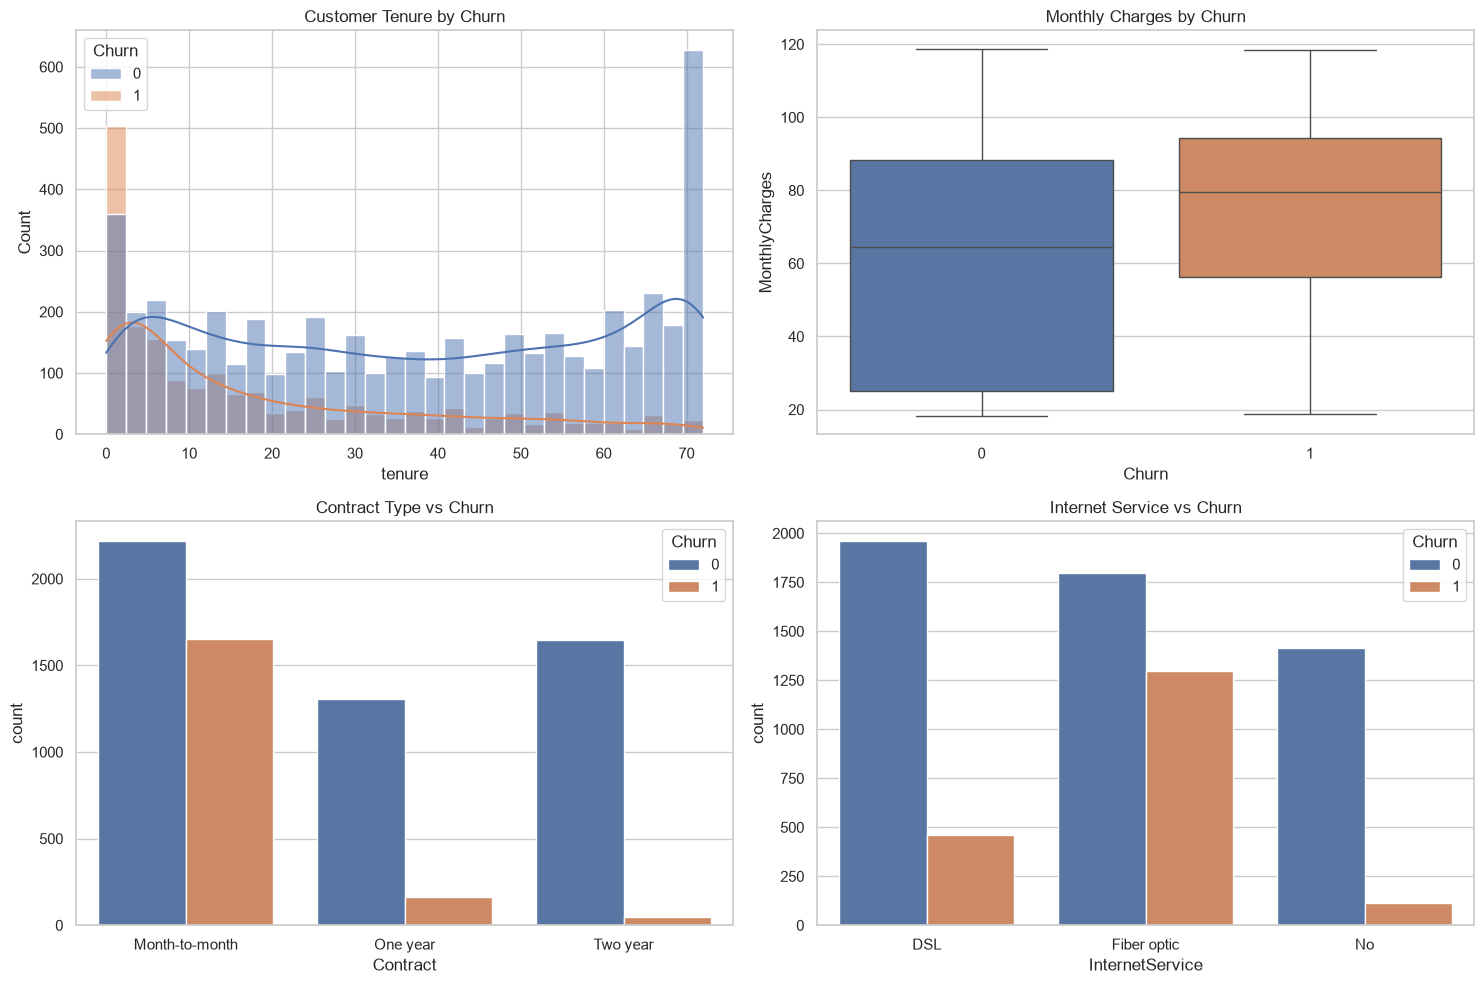

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Customer Tenure by Churn")

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Monthly Charges by Churn")

sns.countplot(
    data=df_clean,
    x="Contract",
    hue="Churn",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Contract Type vs Churn")

sns.countplot(
    data=df_clean,
    x="InternetService",
    hue="Churn",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Internet Service vs Churn")

plt.tight_layout()
plt.show()

## Step 07 - Train-Test Split

In [7]:
X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Features: (5634, 19)
Testing Features: (1409, 19)

Training Target Distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## Step 08 - Preprocessing Pipeline

In [8]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")

Numeric Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline created successfully!


## Step 09 - Class Imbalance Handling

In [9]:
# Calculate class imbalance ratio using training data only
class_counts = y_train.value_counts().sort_index()

negative_count = class_counts.loc[0]
positive_count = class_counts.loc[1]

scale_pos_weight = negative_count / positive_count

print("Non-Churn Customers:", negative_count)
print("Churn Customers:", positive_count)
print(f"XGBoost scale_pos_weight: {scale_pos_weight:.4f}")

print("\nClass Imbalance Strategy:")
print("Random Forest: class_weight='balanced'")
print("XGBoost: scale_pos_weight")

Non-Churn Customers: 4139
Churn Customers: 1495
XGBoost scale_pos_weight: 2.7686

Class Imbalance Strategy:
Random Forest: class_weight='balanced'
XGBoost: scale_pos_weight


## Step 10 - Initialize Machine Learning Models

In [10]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

models = {
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

print("Machine Learning pipelines initialized successfully!")

for name in models:
    print("-", name)

Machine Learning pipelines initialized successfully!
- Random Forest
- XGBoost


## Step 11 - Stratified Cross-Validation

In [11]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, pipeline in models.items():

    print(f"\nEvaluating {name}...")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "f1": "f1",
            "precision": "precision",
            "recall": "recall"
        },
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.style.format({
        "ROC-AUC Mean": "{:.4f}",
        "ROC-AUC Std": "{:.4f}",
        "F1 Mean": "{:.4f}",
        "Precision Mean": "{:.4f}",
        "Recall Mean": "{:.4f}"
    })
)

print("\nCross-validation completed successfully!")


Evaluating Random Forest...

Evaluating XGBoost...


,Model,ROC-AUC Mean,ROC-AUC Std,F1 Mean,Precision Mean,Recall Mean
0,Random Forest,0.8224,0.0101,0.6040,0.5682,0.6448
1,XGBoost,0.8477,0.0101,0.6325,0.5305,0.7833



Cross-validation completed successfully!


## Step 12 - Hyperparameter Tuning

In [12]:
from scipy.stats import randint, uniform

param_distributions = {
    "classifier__n_estimators": randint(150, 351),
    "classifier__max_depth": randint(2, 7),
    "classifier__learning_rate": uniform(0.02, 0.13),
    "classifier__subsample": uniform(0.7, 0.3),
    "classifier__colsample_bytree": uniform(0.7, 0.3),
    "classifier__min_child_weight": randint(1, 7),
    "classifier__reg_lambda": uniform(0.5, 4.5)
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

xgb_search.fit(X_train, y_train)

best_xgb_model = xgb_search.best_estimator_

print("Best Parameters:")
for parameter, value in xgb_search.best_params_.items():
    print(f"{parameter}: {value}")

print(f"\nBest CV ROC-AUC: {xgb_search.best_score_:.4f}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Parameters:
classifier__colsample_bytree: 0.9406590942262119
classifier__learning_rate: 0.029691583678370208
classifier__max_depth: 2
classifier__min_child_weight: 1
classifier__n_estimators: 285
classifier__reg_lambda: 0.5248495270562108
classifier__subsample: 0.9446384285364502

Best CV ROC-AUC: 0.8499


## Step 13 - Hyperparameter Tuning Results

In [13]:
tuning_results = pd.DataFrame(xgb_search.cv_results_)

tuning_summary = tuning_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_fit_time",
        "params"
    ]
].sort_values("rank_test_score")

display(tuning_summary.head(10))

print(f"Baseline XGBoost CV ROC-AUC: {cv_results_df.loc[cv_results_df['Model'] == 'XGBoost', 'ROC-AUC Mean'].iloc[0]:.4f}")
print(f"Tuned XGBoost CV ROC-AUC: {xgb_search.best_score_:.4f}")

,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
11,1,0.849856,0.011853,1.325347,{'classifier__colsample_bytree': 0.94065909422...
12,2,0.847987,0.011854,0.795473,{'classifier__colsample_bytree': 0.91205720315...
2,3,0.847586,0.009624,1.679396,{'classifier__colsample_bytree': 0.98156581270...
5,4,0.846002,0.010542,0.773889,{'classifier__colsample_bytree': 0.83514977559...
4,5,0.843266,0.009669,1.504302,{'classifier__colsample_bytree': 0.93555278841...
3,6,0.841758,0.009434,1.609937,{'classifier__colsample_bytree': 0.82958350559...
7,7,0.841001,0.012254,1.233072,{'classifier__colsample_bytree': 0.77763399448...
6,8,0.839845,0.009712,0.848778,{'classifier__colsample_bytree': 0.72930163420...
14,9,0.836514,0.008743,1.395607,{'classifier__colsample_bytree': 0.79755499660...
10,10,0.836502,0.009964,1.711873,{'classifier__colsample_bytree': 0.78140470953...


Baseline XGBoost CV ROC-AUC: 0.8477
Tuned XGBoost CV ROC-AUC: 0.8499


## Step 14 - Final Model Evaluation

In [14]:
# Fit baseline Random Forest on the training set
rf_pipeline.fit(X_train, y_train)

# Tuned XGBoost is already refitted by RandomizedSearchCV
final_models = {
    "Random Forest": rf_pipeline,
    "Tuned XGBoost": best_xgb_model
}

test_results = []
predictions = {}

for name, model in final_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = {
        "labels": y_pred,
        "probabilities": y_prob
    }

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

print("Final model evaluation completed successfully!")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7637,0.5482,0.6230,0.5832,0.8230
1,Tuned XGBoost,0.7417,0.5085,0.8021,0.6224,0.8454


Final model evaluation completed successfully!


## Step 15 - ROC-AUC Curves

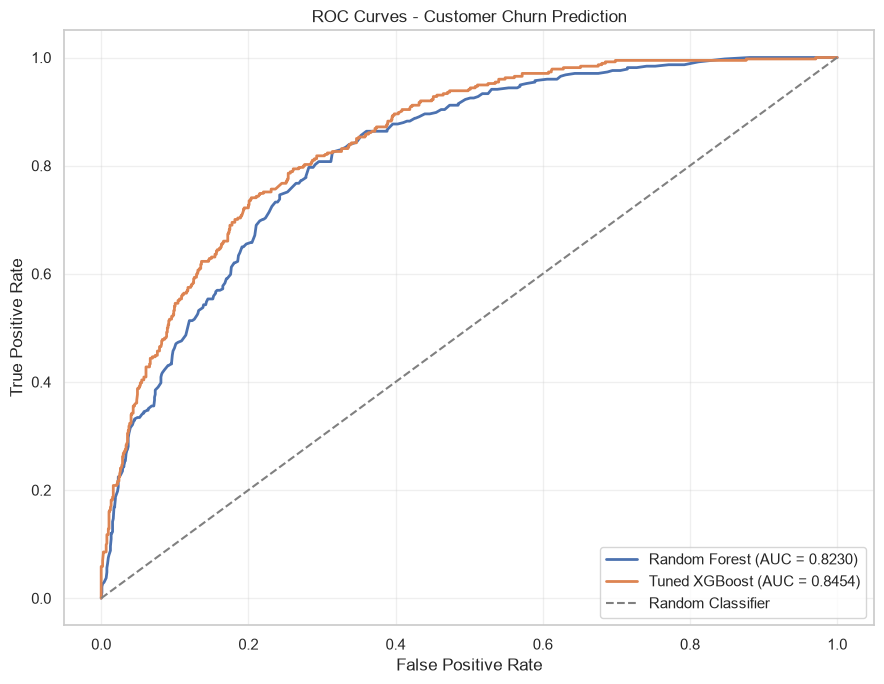

In [15]:
plt.figure(figsize=(9, 7))

for name, result in predictions.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        result["probabilities"]
    )

    auc_score = roc_auc_score(
        y_test,
        result["probabilities"]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curves - Customer Churn Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 16 - Confusion Matrices

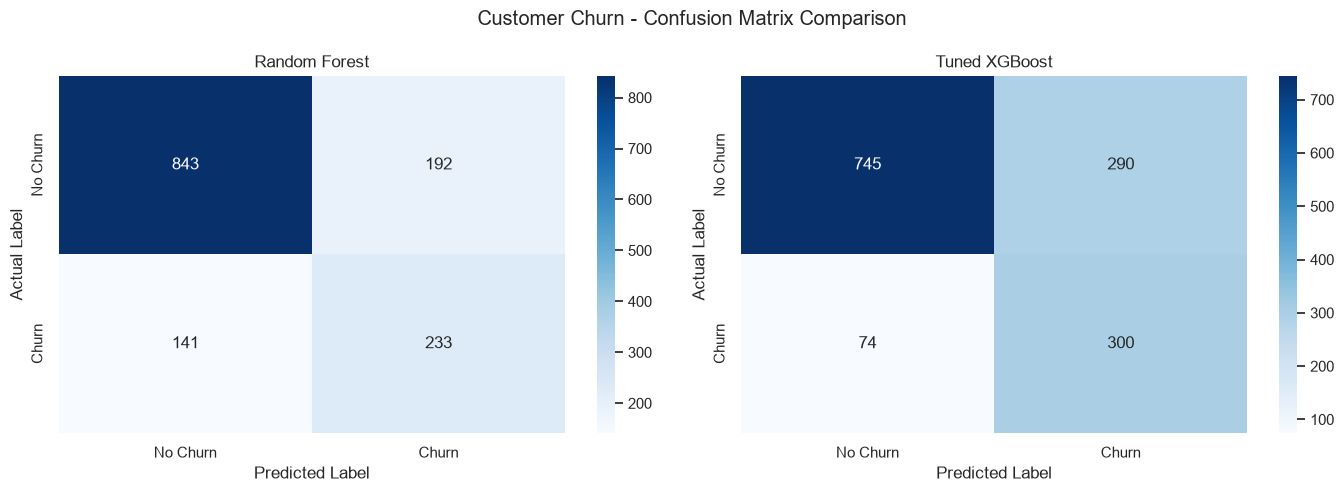

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, result) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_test,
        result["labels"],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Customer Churn - Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

## Step 17 - Classification Reports

In [17]:
for name, result in predictions.items():

    print("=" * 55)
    print(f"{name} - Classification Report")
    print("=" * 55)

    print(
        classification_report(
            y_test,
            result["labels"],
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )

Random Forest - Classification Report
              precision    recall  f1-score   support

    No Churn       0.86      0.81      0.84      1035
       Churn       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409

Tuned XGBoost - Classification Report
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



## Step 18 - Top 10 Feature Importance

,Feature,Importance
0,cat__Contract_Month-to-month,0.422337
1,cat__TechSupport_No,0.091224
2,cat__OnlineSecurity_No,0.080787
3,cat__InternetService_Fiber optic,0.070935
4,cat__PaymentMethod_Electronic check,0.049086
5,cat__Contract_Two year,0.041017
6,cat__InternetService_No,0.032095
7,cat__Contract_One year,0.029332
8,num__tenure,0.022069
9,cat__PaperlessBilling_Yes,0.017587


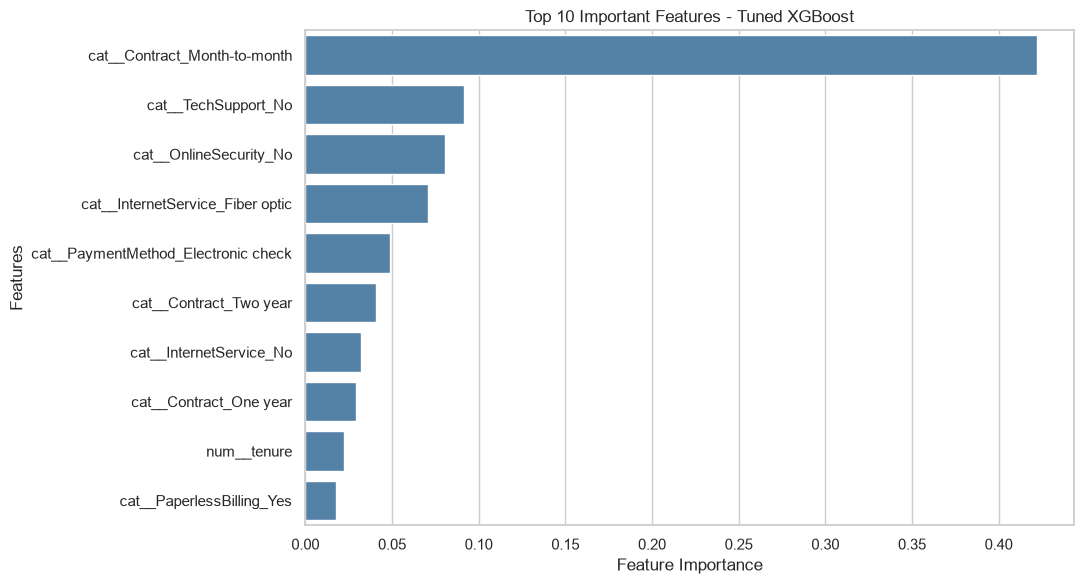

In [18]:
# Extract the trained preprocessing and classification components
trained_preprocessor = best_xgb_model.named_steps["preprocessor"]
trained_classifier = best_xgb_model.named_steps["classifier"]

# Retrieve feature names after one-hot encoding
feature_names = trained_preprocessor.get_feature_names_out()

# Extract XGBoost feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_classifier.feature_importances_
})

importance_df = (
    importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

top_10_features = importance_df.head(10)

display(top_10_features)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Important Features - Tuned XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## Step 19 - Save Best Model

In [19]:
from pathlib import Path
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "customer_churn_xgboost.joblib"

joblib.dump(best_xgb_model, MODEL_PATH)

print("Model saved successfully!")
print("Model Path:", MODEL_PATH.resolve())

Model saved successfully!
Model Path: C:\Users\sudee\OneDrive\Desktop\Datheon-ML-DataScience-Internship\Task-03-Customer-Churn-Prediction\models\customer_churn_xgboost.joblib


## Step 20 - Model Loading and Inference Testing

In [20]:
# Load the saved model
loaded_model = joblib.load(MODEL_PATH)

# Select a customer from the untouched test dataset
sample_customer = X_test.iloc[[0]].copy()

# Generate prediction
prediction = loaded_model.predict(sample_customer)[0]

# Generate churn probability
churn_probability = loaded_model.predict_proba(
    sample_customer
)[0, 1]

print("Customer Churn Prediction")
print("-" * 40)

print(
    "Predicted Status:",
    "Churn" if prediction == 1 else "No Churn"
)

print(f"Churn Probability: {churn_probability:.2%}")

print("\nActual Status:")
print(
    "Churn" if y_test.iloc[0] == 1 else "No Churn"
)

Customer Churn Prediction
----------------------------------------
Predicted Status: No Churn
Churn Probability: 7.71%

Actual Status:
No Churn


## Step 21 - Model Persistence Verification

In [21]:
# Compare predictions before and after model serialization
original_probabilities = best_xgb_model.predict_proba(X_test)[:, 1]
loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]

np.testing.assert_allclose(
    original_probabilities,
    loaded_probabilities,
    rtol=1e-7,
    atol=1e-9
)

assert MODEL_PATH.exists()
assert len(feature_names) == len(
    trained_classifier.feature_importances_
)

print("Model persistence verification passed!")
print("Predictions are consistent after loading.")
print("Feature importance dimensions verified.")

Model persistence verification passed!
Predictions are consistent after loading.
Feature importance dimensions verified.



## Step 22 - Final Project Conclusion

### Project Summary

This project successfully developed and evaluated two ensemble machine learning classifiers, Random Forest and XGBoost, to predict customer churn using the Telco Customer Churn dataset.

The dataset contained 7,043 customer records. Data cleaning, exploratory data analysis, categorical feature encoding, missing value imputation, and class imbalance handling were performed.

Stratified 5-fold cross-validation and randomized hyperparameter optimization were used to develop and evaluate the models.

### Final Test Performance

| Metric | Random Forest | Tuned XGBoost |
|---|---:|---:|
| Accuracy | 76.37% | 74.17% |
| Precision | 54.82% | 50.85% |
| Recall | 62.30% | 80.21% |
| F1-Score | 58.32% | 62.24% |
| ROC-AUC | 82.30% | 84.54% |

### Key Findings

1. Both classifiers exceeded the project's ROC-AUC target of 80%.
2. Tuned XGBoost achieved the highest test ROC-AUC of 84.54%.
3. XGBoost identified 300 of the 374 actual churn customers, achieving 80.21% recall.
4. Random Forest achieved higher overall accuracy and precision, demonstrating a trade-off between false positives and missed churn cases.
5. Month-to-month contracts, lack of technical support, lack of online security, and fiber-optic service were among the most influential predictive features.

### Model Persistence and Inference

The selected XGBoost pipeline was serialized using Joblib.

The saved model was successfully loaded and tested on an unseen customer record. Prediction consistency was verified between the original and reloaded models.

### Limitations

- The dataset represents a historical telecom customer sample and may not reflect current customer behavior.
- The dataset contains class imbalance, which was addressed through class weighting.
- Class weights for XGBoost were calculated from the overall training partition rather than separately within each cross-validation fold.
- Hyperparameter search results may be optimistic because the best configuration was selected using cross-validation.
- Feature importance indicates predictive relevance rather than causality.
- Model performance should be monitored and validated on new data before real-world deployment.
- The saved model is a deployment-oriented artifact, not a fully validated production service.

### Conclusion

Tuned XGBoost was selected as the preferred churn prediction model based on its superior ROC-AUC, F1-score, and churn recall.

The project demonstrates a reproducible, production-oriented machine learning workflow incorporating preprocessing pipelines, model comparison, cross-validation, hyperparameter tuning, evaluation, feature importance analysis, and model persistence.

**Final Test ROC-AUC: 84.54%**

**Project Status: Core internship requirements completed; deployment validation remains future work.**
